In [ ]:

from google.colab import drive
import os
import pandas as pd

# Connect Google Drive
drive.mount('/content/drive')

# Project paths
PROJECT_DIR = "/content/drive/MyDrive/skin_disease_genai"
IMAGE_DIR = os.path.join(PROJECT_DIR, "images")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

# Create output folder
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify required files
print("Project directory:", os.path.isdir(PROJECT_DIR))
print("Images directory:", os.path.isdir(IMAGE_DIR))
print("Metadata CSV:", os.path.isfile(CSV_PATH))
print("Output directory:", OUTPUT_DIR)

if not os.path.isdir(IMAGE_DIR):
    raise FileNotFoundError(f"Images folder not found: {IMAGE_DIR}")

if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(f"Metadata CSV not found: {CSV_PATH}")

metadata = pd.read_csv(CSV_PATH)
print("Metadata rows:", len(metadata))
print("Metadata columns:", metadata.columns.tolist())


Mounted at /content/drive
Project directory: True
Images directory: True
Metadata CSV: True
Output directory: /content/drive/MyDrive/skin_disease_genai/outputs
Metadata rows: 1800
Metadata columns: ['Folder_name', 'Patient_id', 'Image_id', 'Age', 'Sex', 'Leision_location', 'Diagnosis', 'Image_filename', 'Relative_path', 'Is_Duplicate', 'Source_Image_filename']


In [ ]:
import os
from collections import Counter

for disease in sorted(os.listdir(IMAGE_DIR)):
    folder = os.path.join(IMAGE_DIR, disease)

    if os.path.isdir(folder):
        count = sum(
            f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            for f in os.listdir(folder)
        )
        print(f"{disease}: {count} images")

Atopic Dermatitis: 300 images
Contact Dermatitis: 300 images
Eczema: 300 images
Scabies: 300 images
Seborrheic Dermatitis: 300 images
Tinea Corporis: 301 images


In [ ]:

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from tensorflow import keras
from tensorflow.keras import layers

# =========================================================
# CONFIGURATION
# =========================================================
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
HEAD_EPOCHS = 25
FINE_TUNE_EPOCHS = 8

tf.keras.utils.set_random_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# LOAD IMAGES
# =========================================================
metadata = pd.read_csv(CSV_PATH)
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for class_name in sorted(os.listdir(IMAGE_DIR)):
    class_dir = os.path.join(IMAGE_DIR, class_name)

    if not os.path.isdir(class_dir):
        continue

    for filename in os.listdir(class_dir):
        if Path(filename).suffix.lower() in extensions:
            records.append({
                "path": os.path.join(class_dir, filename),
                "filename": filename,
                "label": class_name
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No images found in IMAGE_DIR.")

class_names = sorted(df["label"].unique())
print("Total images:", len(df))
print("Classes:", class_names)
print("\nClass counts:\n", df["label"].value_counts())

# =========================================================
# MATCH METADATA
# =========================================================
required = {"Image_filename", "Source_Image_filename"}

if required.issubset(metadata.columns):
    metadata["Image_filename"] = (
        metadata["Image_filename"].astype(str).map(
            lambda x: Path(x).name
        )
    )
    metadata = metadata.drop_duplicates(
        subset=["Image_filename"], keep="first"
    )

    df = df.merge(
        metadata,
        left_on="filename",
        right_on="Image_filename",
        how="left",
        suffixes=("", "_csv")
    )

    matched = df["Source_Image_filename"].notna().sum()
    print(f"\nImages matched to source metadata: {matched}/{len(df)}")
else:
    print("WARNING: Source filename columns are missing.")

# =========================================================
# GROUP COPIES WITH THEIR ORIGINAL IMAGES
# =========================================================
# Source_Image_filename must refer to the ORIGINAL image name.
# Patient ID is used when available and complete.
if "Patient_id" in df.columns and df["Patient_id"].notna().all():
    groups = df["Patient_id"].astype(str)
    print("Splitting by patient ID.")
elif (
    "Source_Image_filename" in df.columns
    and df["Source_Image_filename"].notna().all()
):
    groups = (
        df["label"].astype(str) + "::" +
        df["Source_Image_filename"].astype(str)
    )
    print("Splitting by source image.")
else:
    raise ValueError(
        "Cannot reliably identify copied images. Check that "
        "Source_Image_filename matches the actual original filename "
        "for every copied image, and that Patient_id is complete."
    )

df["group_id"] = groups.values

# Ensure all copies of a source are grouped consistently.
print("Unique groups:", df["group_id"].nunique())

# =========================================================
# GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT
# =========================================================
# Try several deterministic group splits until each split
# contains all classes. No group may occur in multiple splits.
def make_group_split(frame, test_size, seed, required_classes):
    for offset in range(100):
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=test_size,
            random_state=seed + offset
        )
        left_idx, right_idx = next(
            splitter.split(
                frame,
                frame["label"],
                groups=frame["group_id"]
            )
        )

        left = frame.iloc[left_idx].copy()
        right = frame.iloc[right_idx].copy()

        if (
            set(left["label"].unique()) == required_classes
            and set(right["label"].unique()) == required_classes
        ):
            return left, right

    raise ValueError(
        "Could not create a group split containing every class. "
        "Inspect the patient/source groups and class distribution."
    )

all_classes = set(class_names)

trainval_df, test_df = make_group_split(
    df, test_size=0.20, seed=SEED,
    required_classes=all_classes
)

train_df, val_df = make_group_split(
    trainval_df, test_size=0.20, seed=SEED + 100,
    required_classes=all_classes
)

assert set(train_df.group_id).isdisjoint(set(val_df.group_id))
assert set(train_df.group_id).isdisjoint(set(test_df.group_id))
assert set(val_df.group_id).isdisjoint(set(test_df.group_id))

print("\nTrain images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("\nTrain distribution:\n", train_df["label"].value_counts())
print("\nValidation distribution:\n", val_df["label"].value_counts())
print("\nTest distribution:\n", test_df["label"].value_counts())

# Save split details for auditing.
for name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    frame[["path", "filename", "label", "group_id"]].to_csv(
        os.path.join(OUTPUT_DIR, f"{name}_split.csv"),
        index=False
    )

# =========================================================
# TF.DATA PIPELINE
# =========================================================
AUTOTUNE = tf.data.AUTOTUNE
label_to_index = {name: i for i, name in enumerate(class_names)}

def load_image(path, label):
    content = tf.io.read_file(path)
    image = tf.io.decode_image(
        content, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(frame, training=False):
    paths = frame["path"].astype(str).values
    labels = frame["label"].map(label_to_index).values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(frame), seed=SEED, reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# =========================================================
# CLASS WEIGHTS
# =========================================================
y_train = train_df["label"].map(label_to_index).values
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)
class_weights = {
    i: float(weight) for i, weight in enumerate(weights)
}
print("\nClass weights:", class_weights)

# =========================================================
# MODEL: EFFICIENTNETB0
# =========================================================
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10)
], name="data_augmentation")

inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)

backbone = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
backbone.trainable = False

x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.40)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

best_path = os.path.join(OUTPUT_DIR, "skin_disnet_best.keras")

# =========================================================
# STAGE 1: CLASSIFICATION HEAD
# =========================================================
callbacks1 = [
    keras.callbacks.ModelCheckpoint(
        best_path, monitor="val_loss",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3,
        patience=2, min_lr=1e-7, verbose=1
    )
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks1
)

# =========================================================
# STAGE 2: FINE-TUNING
# =========================================================
backbone.trainable = True

for layer in backbone.layers[:-30]:
    layer.trainable = False

# Keep BatchNorm frozen for stable fine-tuning.
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks2 = [
    keras.callbacks.ModelCheckpoint(
        best_path, monitor="val_loss",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3,
        patience=2, min_lr=1e-7, verbose=1
    )
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks2
)

# Use the best validation-loss checkpoint.
model = keras.models.load_model(best_path)

# =========================================================
# TEST EVALUATION
# =========================================================
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nTest accuracy:", round(test_accuracy * 100, 2), "%")
print("Macro F1:", round(macro_f1, 4))

report = classification_report(
    y_true, y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
)
print("\nClassification report:\n", report)

with open(
    os.path.join(OUTPUT_DIR, "classification_report.txt"), "w"
) as f:
    f.write(report)

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(len(class_names))
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=class_names
)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# =========================================================
# SAVE FINAL ARTIFACTS TO DRIVE
# =========================================================
final_model_path = os.path.join(
    OUTPUT_DIR, "skin_disnet_final.keras"
)
model.save(final_model_path)

with open(
    os.path.join(OUTPUT_DIR, "class_names.json"), "w"
) as f:
    json.dump(class_names, f, indent=2)

with open(
    os.path.join(OUTPUT_DIR, "test_metrics.json"), "w"
) as f:
    json.dump({
        "test_accuracy": float(test_accuracy),
        "macro_f1": float(macro_f1),
        "classes": class_names,
        "train_images": len(train_df),
        "validation_images": len(val_df),
        "test_images": len(test_df)
    }, f, indent=2)

# Plot training history.
all_acc = history1.history["accuracy"] + history2.history["accuracy"]
all_val_acc = (
    history1.history["val_accuracy"] +
    history2.history["val_accuracy"]
)
all_loss = history1.history["loss"] + history2.history["loss"]
all_val_loss = (
    history1.history["val_loss"] +
    history2.history["val_loss"]
)

plt.figure(figsize=(10, 4))
plt.plot(all_acc, label="Training accuracy")
plt.plot(all_val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve.png"), dpi=200)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(all_loss, label="Training loss")
plt.plot(all_val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=200)
plt.show()

print("\nTRAINING COMPLETE")
print("Saved model:", final_model_path)
print("Saved reports:", OUTPUT_DIR)
print("Do not interpret model predictions as a confirmed diagnosis.")


Total images: 1801
Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']

Class counts:
 label
Tinea Corporis           301
Atopic Dermatitis        300
Contact Dermatitis       300
Eczema                   300
Scabies                  300
Seborrheic Dermatitis    300
Name: count, dtype: int64

Images matched to source metadata: 1800/1801


ValueError: Cannot reliably identify copied images. Check that Source_Image_filename matches the actual original filename for every copied image, and that Patient_id is complete.

In [ ]:
import os
import pandas as pd
from pathlib import Path

metadata = pd.read_csv(CSV_PATH)

# Get actual image filenames from the folders
image_files = []

for root, dirs, files in os.walk(IMAGE_DIR):
    for filename in files:
        if Path(filename).suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            image_files.append({
                "filename": filename,
                "path": os.path.join(root, filename)
            })

actual = pd.DataFrame(image_files)

metadata["Image_filename"] = (
    metadata["Image_filename"].astype(str).map(
        lambda x: Path(x).name
    )
)

# Find image files without a metadata match
unmatched = actual[
    ~actual["filename"].isin(metadata["Image_filename"])
]

print("Actual image files:", len(actual))
print("Metadata rows:", len(metadata))
print("Unmatched images:", len(unmatched))
print(unmatched.to_string(index=False))

print("\nMissing source filenames in metadata:")
print(
    metadata[
        metadata["Source_Image_filename"].isna()
        | (metadata["Source_Image_filename"].astype(str).str.strip() == "")
    ][["Image_filename", "Source_Image_filename", "Diagnosis"]]
)

Actual image files: 1801
Metadata rows: 1800
Unmatched images: 1
        filename                                                                             path
TC (192) (1).jpg /content/drive/MyDrive/skin_disease_genai/images/Tinea Corporis/TC (192) (1).jpg

Missing source filenames in metadata:
Empty DataFrame
Columns: [Image_filename, Source_Image_filename, Diagnosis]
Index: []


Metadata rows after repair: 1801
Images found: 1801
Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']

Class counts:
 label
Tinea Corporis           301
Atopic Dermatitis        300
Contact Dermatitis       300
Eczema                   300
Scabies                  300
Seborrheic Dermatitis    300
Name: count, dtype: int64
Images matched to metadata: 1801/1801
Unique source groups: 1324

Train: 1168
Validation: 267
Test: 366

Train classes:
 label
Atopic Dermatitis        206
Seborrheic Dermatitis    197
Scabies                  193
Contact Dermatitis       192
Eczema                   190
Tinea Corporis           190
Name: count, dtype: int64

Validation classes:
 label
Eczema                   52
Contact Dermatitis       50
Tinea Corporis           50
Scabies                  46
Seborrheic Dermatitis    37
Atopic Dermatitis        32
Name: count, dtype: int64

Test classes:
 label
Seborrheic Dermatitis    66
Atopic Der

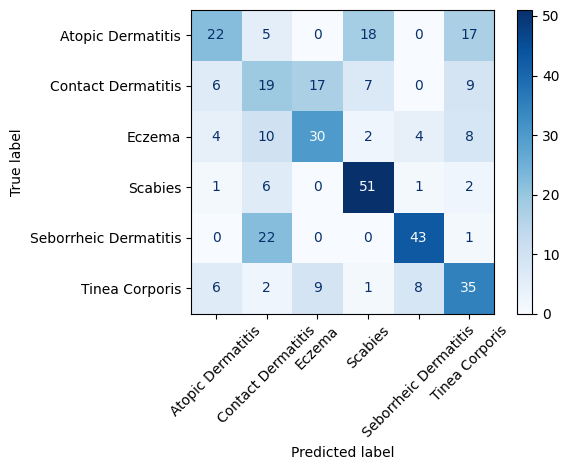


TRAINING COMPLETE
Model saved: /content/drive/MyDrive/skin_disease_genai/outputs/skin_disnet_final.keras
Reports saved in: /content/drive/MyDrive/skin_disease_genai/outputs
Predictions are not a confirmed medical diagnosis.


In [ ]:

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from tensorflow import keras
from tensorflow.keras import layers

# =========================================================
# CONFIGURATION
# =========================================================
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

# =========================================================
# LOAD METADATA AND ADD THE MISSING IMAGE ROW
# =========================================================
metadata = pd.read_csv(CSV_PATH)
metadata["Image_filename"] = metadata["Image_filename"].astype(str).map(
    lambda x: Path(x).name
)

missing_filename = "TC (192) (1).jpg"

if missing_filename not in set(metadata["Image_filename"]):
    new_row = {col: np.nan for col in metadata.columns}
    new_row["Image_filename"] = missing_filename
    new_row["Diagnosis"] = "Tinea Corporis"

    # This filename looks like a copy of TC (192).jpg.
    # Verify that this original file exists before relying on this grouping.
    new_row["Source_Image_filename"] = "TC (192).jpg"

    metadata = pd.concat(
        [metadata, pd.DataFrame([new_row])],
        ignore_index=True
    )

print("Metadata rows after repair:", len(metadata))

# =========================================================
# BUILD IMAGE INDEX
# =========================================================
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []

for class_name in sorted(os.listdir(IMAGE_DIR)):
    class_dir = os.path.join(IMAGE_DIR, class_name)

    if not os.path.isdir(class_dir):
        continue

    for filename in os.listdir(class_dir):
        if Path(filename).suffix.lower() in extensions:
            records.append({
                "path": os.path.join(class_dir, filename),
                "filename": filename,
                "label": class_name
            })

df = pd.DataFrame(records)
class_names = sorted(df["label"].unique())

print("Images found:", len(df))
print("Classes:", class_names)
print("\nClass counts:\n", df["label"].value_counts())

# =========================================================
# MATCH CSV TO IMAGE FILENAMES
# =========================================================
metadata = metadata.drop_duplicates(
    subset=["Image_filename"], keep="first"
)

df = df.merge(
    metadata,
    left_on="filename",
    right_on="Image_filename",
    how="left",
    suffixes=("", "_csv")
)

matched = df["Image_filename"].notna().sum()
print(f"Images matched to metadata: {matched}/{len(df)}")

# Labels are taken from the actual folder names.
# This protects against inconsistent diagnosis spelling in the CSV.
if df["Image_filename"].isna().any():
    print("Unmatched filenames:")
    print(df.loc[df["Image_filename"].isna(), ["filename", "path"]])
    raise ValueError("Some image files still do not match metadata.")

# =========================================================
# GROUP ORIGINAL IMAGES AND COPIES
# =========================================================
source = df["Source_Image_filename"].fillna("").astype(str).str.strip()

# Missing source mappings fall back to the file's own name.
# Such fallbacks must be checked for duplicates.
df["group_id"] = np.where(
    source.ne("") & source.ne("nan"),
    df["label"].astype(str) + "::" + source.map(lambda x: Path(x).name),
    df["label"].astype(str) + "::" + df["filename"].astype(str)
)

# If a source file exists in the same class folder, assign it to
# the same group as its copies.
for idx, row in df.iterrows():
    source_name = str(row["filename"])
    if source_name.endswith(" (1).jpg"):
        candidate = source_name.replace(" (1).jpg", ".jpg")
        candidate_path = os.path.join(
            IMAGE_DIR, row["label"], candidate
        )
        if os.path.isfile(candidate_path):
            df.loc[idx, "group_id"] = (
                str(row["label"]) + "::" + candidate
            )

print("Unique source groups:", df["group_id"].nunique())

# =========================================================
# GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT
# =========================================================
all_classes = set(class_names)

def group_split(frame, test_size, seed):
    for attempt in range(100):
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=test_size,
            random_state=seed + attempt
        )
        left_idx, right_idx = next(
            splitter.split(
                frame, frame["label"], groups=frame["group_id"]
            )
        )
        left = frame.iloc[left_idx].copy()
        right = frame.iloc[right_idx].copy()

        if (set(left["label"]) == all_classes and
                set(right["label"]) == all_classes):
            return left, right

    raise ValueError(
        "Could not make a split containing all six classes. "
        "Check patient/source groups and try a different seed."
    )

trainval_df, test_df = group_split(df, 0.20, SEED)
train_df, val_df = group_split(trainval_df, 0.20, SEED + 100)

assert set(train_df.group_id).isdisjoint(val_df.group_id)
assert set(train_df.group_id).isdisjoint(test_df.group_id)
assert set(val_df.group_id).isdisjoint(test_df.group_id)

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("\nTrain classes:\n", train_df["label"].value_counts())
print("\nValidation classes:\n", val_df["label"].value_counts())
print("\nTest classes:\n", test_df["label"].value_counts())

for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    frame[["path", "filename", "label", "group_id"]].to_csv(
        os.path.join(OUTPUT_DIR, f"{split_name}_split.csv"),
        index=False
    )

# =========================================================
# IMAGE PIPELINE
# =========================================================
AUTOTUNE = tf.data.AUTOTUNE
label_to_index = {name: i for i, name in enumerate(class_names)}

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(frame, training=False):
    paths = frame["path"].astype(str).values
    labels = frame["label"].map(label_to_index).values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            len(frame), seed=SEED, reshuffle_each_iteration=True
        )
    return ds.map(
        load_image, num_parallel_calls=AUTOTUNE
    ).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# =========================================================
# CLASS WEIGHTS
# =========================================================
y_train = train_df["label"].map(label_to_index).values
weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)
class_weights = {
    i: float(value) for i, value in enumerate(weight_values)
}
print("Class weights:", class_weights)

# =========================================================
# EFFICIENTNETB0
# =========================================================
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10)
], name="augmentation")

inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)

backbone = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
backbone.trainable = False

x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

model = keras.Model(inputs, outputs)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

best_path = os.path.join(OUTPUT_DIR, "skin_disnet_best.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        best_path, monitor="val_loss",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3,
        patience=2, min_lr=1e-7, verbose=1
    )
]

print("\nSTAGE 1: Training classification head")
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=callbacks
)

# =========================================================
# FINE-TUNE LAST BACKBONE LAYERS
# =========================================================
backbone.trainable = True

for layer in backbone.layers[:-30]:
    layer.trainable = False

for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks2 = [
    keras.callbacks.ModelCheckpoint(
        best_path, monitor="val_loss",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3,
        patience=2, min_lr=1e-7, verbose=1
    )
]

print("\nSTAGE 2: Fine-tuning")
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks2
)

model = keras.models.load_model(best_path)

# =========================================================
# TEST EVALUATION
# =========================================================
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

report = classification_report(
    y_true, y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
)

print("\nTEST ACCURACY:", round(test_accuracy * 100, 2), "%")
print("MACRO F1:", round(macro_f1, 4))
print("\n", report)

with open(
    os.path.join(OUTPUT_DIR, "classification_report.txt"), "w"
) as f:
    f.write(report)

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(len(class_names))
)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# =========================================================
# SAVE FINAL OUTPUTS TO DRIVE
# =========================================================
final_path = os.path.join(OUTPUT_DIR, "skin_disnet_final.keras")
model.save(final_path)

with open(os.path.join(OUTPUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=2)

with open(os.path.join(OUTPUT_DIR, "test_metrics.json"), "w") as f:
    json.dump({
        "test_accuracy": float(test_accuracy),
        "macro_f1": float(macro_f1),
        "classes": class_names,
        "train_images": len(train_df),
        "validation_images": len(val_df),
        "test_images": len(test_df)
    }, f, indent=2)

print("\nTRAINING COMPLETE")
print("Model saved:", final_path)
print("Reports saved in:", OUTPUT_DIR)
print("Predictions are not a confirmed medical diagnosis.")


In [ ]:
import pandas as pd
import os

out = os.path.join(PROJECT_DIR, "outputs")

train = pd.read_csv(os.path.join(out, "train_split.csv"))
val = pd.read_csv(os.path.join(out, "validation_split.csv"))
test = pd.read_csv(os.path.join(out, "test_split.csv"))

for name, frame in [
    ("Train", train), ("Validation", val), ("Test", test)
]:
    print(f"\n{name}: {len(frame)} images")
    print(frame["label"].value_counts())

train_groups = set(train["group_id"])
val_groups = set(val["group_id"])
test_groups = set(test["group_id"])

print("\nTrain/validation overlap:", len(train_groups & val_groups))
print("Train/test overlap:", len(train_groups & test_groups))
print("Validation/test overlap:", len(val_groups & test_groups))


Train: 1168 images
label
Atopic Dermatitis        206
Seborrheic Dermatitis    197
Scabies                  193
Contact Dermatitis       192
Eczema                   190
Tinea Corporis           190
Name: count, dtype: int64

Validation: 267 images
label
Eczema                   52
Contact Dermatitis       50
Tinea Corporis           50
Scabies                  46
Seborrheic Dermatitis    37
Atopic Dermatitis        32
Name: count, dtype: int64

Test: 366 images
label
Seborrheic Dermatitis    66
Atopic Dermatitis        62
Tinea Corporis           61
Scabies                  61
Contact Dermatitis       58
Eczema                   58
Name: count, dtype: int64

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
